# U1 - Patrones espaciales de Citi Bike

**Integrante:** Cristhian Chuquitarqui Chura  
**Tipo:** Predictiva sin tiempo real (Batch)

## Pregunta de análisis

¿Qué zonas concentran históricamente la actividad de Citi Bike y qué zonas presentan mayor probabilidad de registrar alta actividad futura?

## Objetivo

Analizar espacialmente los viajes de Citi Bike, identificar las zonas con mayor concentración histórica y construir una estimación de alta actividad futura por zona.

In [1]:
# Importamos librerias e iniciamos Spark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("CitiBike_U1_Patrones_Espaciales")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Spark iniciado correctamente")
print("Version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/11 19:03:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark iniciado correctamente
Version: 4.2.0


In [2]:
# Cargamos los 5 archivos CSV de Citi Bike
df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("/opt/data/raw/*.csv")
)

print("Total de registros:", df.count())

26/09/11 19:03:30 WARN FileStreamSink: Assume no metadata directory. Error while looking for metadata directory in the path: /opt/data/raw/*.csv.
java.io.FileNotFoundException: File /opt/data/raw/*.csv does not exist
	at org.apache.hadoop.fs.RawLocalFileSystem.deprecatedGetFileStatus(RawLocalFileSystem.java:980)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileLinkStatusInternal(RawLocalFileSystem.java:1301)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileStatus(RawLocalFileSystem.java:970)
	at org.apache.hadoop.fs.FilterFileSystem.getFileStatus(FilterFileSystem.java:462)
	at org.apache.spark.sql.execution.streaming.sinks.FileStreamSink$.hasMetadata(FileStreamSink.scala:58)
	at org.apache.spark.sql.execution.datasources.DataSource.resolveRelation(DataSource.scala:394)
	at org.apache.spark.sql.catalyst.analysis.ResolveDataSource.org$apache$spark$sql$catalyst$analysis$ResolveDataSource$$loadV1BatchSource(ResolveDataSource.scala:210)
	at org.apache.spark.sql.catalyst.analysis.Resolve

Total de registros: 4993137


In [3]:
# Seleccionamos las variables necesarias para el analisis espacial
df_espacial = df.select(
    "ride_id",
    "started_at",
    "start_station_id",
    "end_station_id",
    "start_lat",
    "start_lng",
    "end_lat",
    "end_lng"
).dropna(
    subset=["start_lat", "start_lng", "end_lat", "end_lng"]
)

df_espacial.show(5, truncate=False)

+----------------+-----------------------+----------------+--------------+------------------+------------------+-----------------+------------------+
|ride_id         |started_at             |start_station_id|end_station_id|start_lat         |start_lng         |end_lat          |end_lng           |
+----------------+-----------------------+----------------+--------------+------------------+------------------+-----------------+------------------+
|FB2708B4615FC7B1|2026-07-04 15:52:29.356|6107.08         |5500.02       |40.74056423633952 |-73.99852573871613|40.72170005235607|-74.00238141417502|
|6D9C1D2C900149A3|2026-07-09 00:31:21.213|5492.05         |5500.02       |40.722103786686034|-73.99724900722504|40.72170005235607|-74.00238141417502|
|C945BA79D67B1EAE|2026-07-02 22:51:30.134|7680.03         |7634.01       |40.804213         |-73.96699104      |40.8008363       |-73.9664492472    |
|9896AB3B453BED3B|2026-07-01 15:50:55.534|5492.05         |5880.02       |40.722103786686034|-73.997

In [6]:
# 3. Seleccionamos las variables de nuestra dimension
df_espacial = (
    df.select(
        "ride_id",
        "started_at",
        "start_station_id",
        "end_station_id",
        "start_lat",
        "start_lng",
        "end_lat",
        "end_lng"
    )
    .dropna(
        subset=[
            "start_lat",
            "start_lng",
            "end_lat",
            "end_lng"
        ]
    )
)

print("Registros validos:", df_espacial.count())

[Stage 7:>                                                        (0 + 20) / 20]

Registros validos: 4975426


In [7]:
# 4. Creamos zonas espaciales con coordenadas redondeadas
df_zonas = (
    df_espacial
    .withColumn("start_zone_lat", F.round("start_lat", 2))
    .withColumn("start_zone_lng", F.round("start_lng", 2))
    .withColumn("end_zone_lat", F.round("end_lat", 2))
    .withColumn("end_zone_lng", F.round("end_lng", 2))
    .withColumn(
        "start_zone",
        F.concat_ws("_", "start_zone_lat", "start_zone_lng")
    )
    .withColumn(
        "end_zone",
        F.concat_ws("_", "end_zone_lat", "end_zone_lng")
    )
)

df_zonas.select(
    "start_zone",
    "end_zone"
).show(10, truncate=False)

+------------+------------+
|start_zone  |end_zone    |
+------------+------------+
|40.74_-74.0 |40.72_-74.0 |
|40.72_-74.0 |40.72_-74.0 |
|40.8_-73.97 |40.8_-73.97 |
|40.72_-74.0 |40.73_-74.0 |
|40.75_-73.99|40.78_-73.96|
|40.79_-73.98|40.78_-73.96|
|40.73_-73.99|40.73_-74.0 |
|40.72_-74.0 |40.73_-74.0 |
|40.79_-73.98|40.78_-73.96|
|40.72_-74.0 |40.73_-74.0 |
+------------+------------+
only showing top 10 rows


In [8]:
# 5. Calculamos viajes de origen y destino por zona
origen = (
    df_zonas
    .groupBy("start_zone")
    .agg(F.count("ride_id").alias("viajes_origen"))
)

destino = (
    df_zonas
    .groupBy("end_zone")
    .agg(F.count("ride_id").alias("viajes_destino"))
)

In [9]:
# Sumamos origen y destino para obtener la actividad total
actividad_total = (
    origen
    .withColumnRenamed("start_zone", "zona")
    .join(
        destino.withColumnRenamed("end_zone", "zona"),
        on="zona",
        how="outer"
    )
    .fillna(0)
    .withColumn(
        "actividad_total",
        F.col("viajes_origen") + F.col("viajes_destino")
    )
    .orderBy(F.desc("actividad_total"))
)

actividad_total.show(10, truncate=False)

[Stage 12:==============>                                         (5 + 15) / 20]

+------------+-------------+--------------+---------------+
|zona        |viajes_origen|viajes_destino|actividad_total|
+------------+-------------+--------------+---------------+
|40.72_-73.99|146770       |147772        |294542         |
|40.73_-73.99|145525       |146253        |291778         |
|40.74_-73.99|132240       |132352        |264592         |
|40.75_-73.99|128567       |127686        |256253         |
|40.74_-74.0 |118641       |118713        |237354         |
|40.75_-74.0 |111961       |112109        |224070         |
|40.76_-73.99|109475       |107946        |217421         |
|40.73_-74.0 |108296       |108993        |217289         |
|40.74_-73.98|105971       |105159        |211130         |
|40.73_-73.98|106105       |104797        |210902         |
+------------+-------------+--------------+---------------+
only showing top 10 rows


Crear actividad por hora y actividad futura

In [10]:
# 6. Agrupamos los viajes de cada zona por hora
actividad_horaria = (
    df_zonas
    .withColumn(
        "fecha_hora",
        F.date_trunc("hour", "started_at")
    )
    .groupBy(
        "start_zone",
        "start_zone_lat",
        "start_zone_lng",
        "fecha_hora"
    )
    .agg(
        F.count("ride_id").alias("viajes_hora")
    )
    .withColumn("hora", F.hour("fecha_hora"))
    .withColumn("dia_semana", F.dayofweek("fecha_hora"))
)

In [11]:
# Obtenemos la actividad de la siguiente observacion de cada zona
ventana = (
    Window
    .partitionBy("start_zone")
    .orderBy("fecha_hora")
)

modelo_df = (
    actividad_horaria
    .withColumn(
        "viajes_futuros",
        F.lead("viajes_hora").over(ventana)
    )
    .dropna(subset=["viajes_futuros"])
)

In [12]:
# 7. Definimos alta actividad usando el percentil 75
umbral = modelo_df.approxQuantile(
    "viajes_futuros",
    [0.75],
    0.01
)[0]

print("Umbral de alta actividad:", umbral)

[Stage 21:=============================>                            (1 + 1) / 2]

Umbral de alta actividad: 27.0


In [13]:
# Marcamos 1 si la actividad futura es alta y 0 si no
modelo_df = modelo_df.withColumn(
    "alta_actividad",
    F.when(
        F.col("viajes_futuros") >= umbral,
        1
    ).otherwise(0)
)

modelo_df.groupBy("alta_actividad").count().show()

[Stage 26:=====================================================>  (19 + 1) / 20]

+--------------+------+
|alta_actividad| count|
+--------------+------+
|             1| 45581|
|             0|133819|
+--------------+------+



Modelo predictivo y evaluación

In [14]:
# 8. Preparamos y entrenamos un Random Forest ligero
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

assembler = VectorAssembler(
    inputCols=[
        "start_zone_lat",
        "start_zone_lng",
        "hora",
        "dia_semana",
        "viajes_hora"
    ],
    outputCol="features"
)

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="alta_actividad",
    numTrees=15,
    maxDepth=5,
    seed=42
)

pipeline = Pipeline(
    stages=[assembler, rf]
)

train, test = modelo_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

modelo = pipeline.fit(train)

predicciones = modelo.transform(test)

print("Modelo entrenado correctamente")

[Stage 85:=====================================================>  (19 + 1) / 20]

Modelo entrenado correctamente


In [15]:
# Mostramos algunas predicciones
predicciones.select(
    "start_zone",
    "viajes_hora",
    "viajes_futuros",
    "alta_actividad",
    "prediction"
).show(20, truncate=False)

[Stage 88:==============>                                         (5 + 15) / 20]

+------------+-----------+--------------+--------------+----------+
|start_zone  |viajes_hora|viajes_futuros|alta_actividad|prediction|
+------------+-----------+--------------+--------------+----------+
|40.62_-74.03|1          |1             |0             |0.0       |
|40.62_-74.03|3          |1             |0             |0.0       |
|40.62_-74.03|4          |6             |0             |0.0       |
|40.62_-74.03|2          |8             |0             |0.0       |
|40.62_-74.03|3          |2             |0             |0.0       |
|40.62_-74.03|3          |6             |0             |0.0       |
|40.62_-74.03|4          |3             |0             |0.0       |
|40.62_-74.03|5          |11            |0             |0.0       |
|40.62_-74.03|5          |4             |0             |0.0       |
|40.62_-74.03|4          |4             |0             |0.0       |
|40.62_-74.03|4          |2             |0             |0.0       |
|40.62_-74.03|2          |1             |0      

In [16]:
# Calculamos la exactitud del modelo
evaluador = MulticlassClassificationEvaluator(
    labelCol="alta_actividad",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluador.evaluate(predicciones)

print("Accuracy:", round(accuracy, 4))

[Stage 94:=======================================>                (14 + 6) / 20]

Accuracy: 0.9317


In [19]:
# Instalamos matplotlib dentro del entorno actual
!pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 411.8 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 1.6 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 1.7 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.8/122.8 kB 1.9 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 1.7 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 1.9 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [20]:
# Importamos las librerias para graficar
import matplotlib.pyplot as plt
import pandas as pd

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

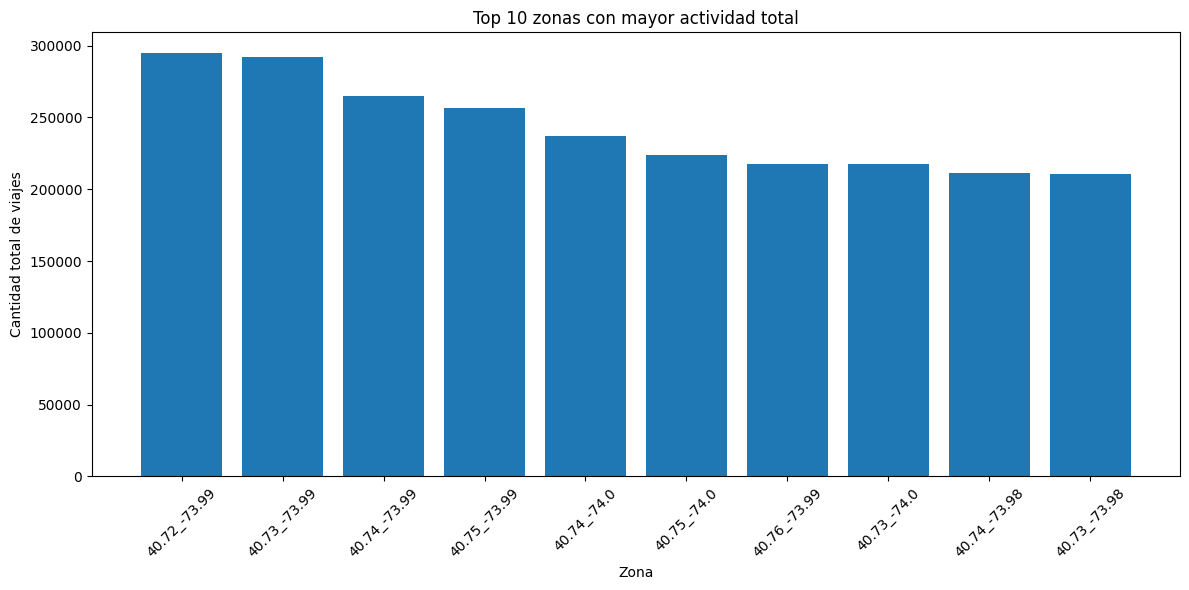

In [23]:
# Obtenemos las 10 zonas con mayor actividad
top10 = actividad_total.limit(10).toPandas()

plt.figure(figsize=(12,6))

plt.bar(
    top10["zona"],
    top10["actividad_total"]
)

plt.title("Top 10 zonas con mayor actividad total")
plt.xlabel("Zona")
plt.ylabel("Cantidad total de viajes")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

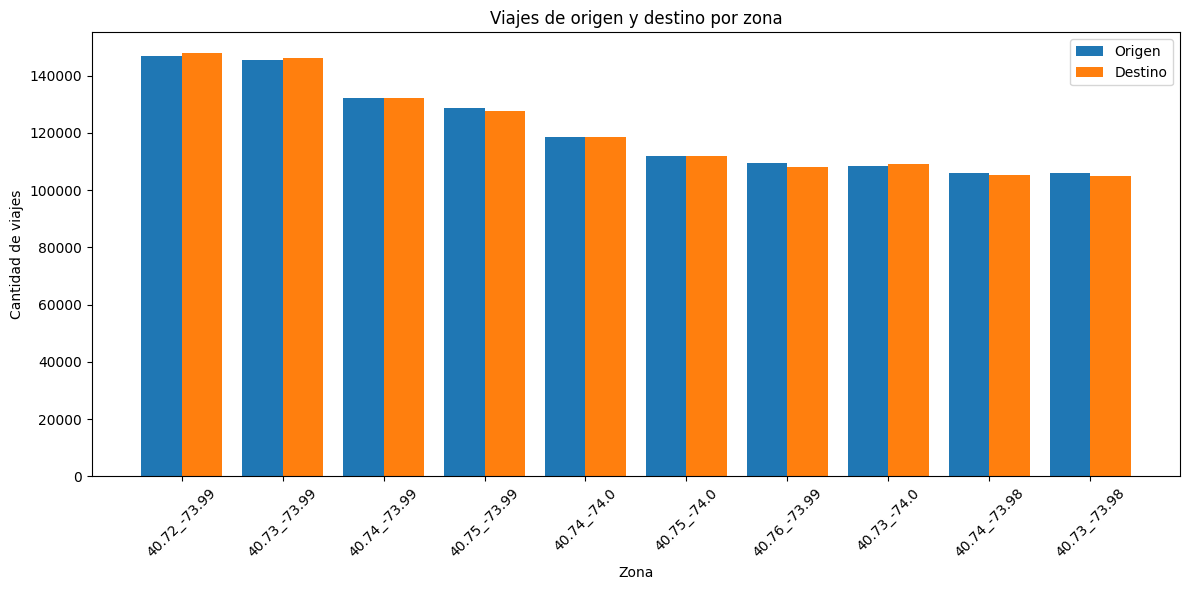

In [24]:
# Comparamos los viajes de origen y destino de las 10 zonas principales
top10 = actividad_total.limit(10).toPandas()

x = range(len(top10))
ancho = 0.4

plt.figure(figsize=(12,6))

plt.bar(
    [i - ancho/2 for i in x],
    top10["viajes_origen"],
    width=ancho,
    label="Origen"
)

plt.bar(
    [i + ancho/2 for i in x],
    top10["viajes_destino"],
    width=ancho,
    label="Destino"
)

plt.title("Viajes de origen y destino por zona")
plt.xlabel("Zona")
plt.ylabel("Cantidad de viajes")

plt.xticks(
    list(x),
    top10["zona"],
    rotation=45
)

plt.legend()
plt.tight_layout()
plt.show()

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

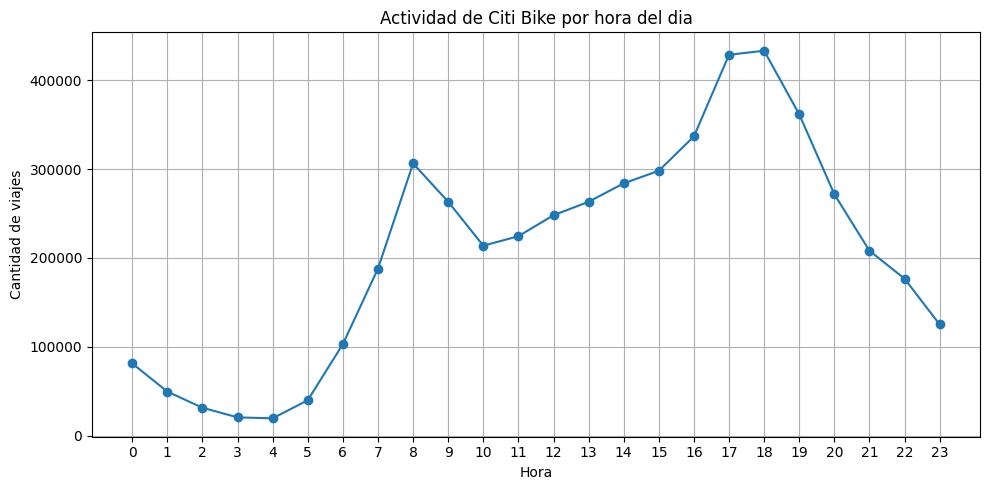

In [25]:
# Calculamos cuantos viajes se realizan en cada hora del dia
actividad_hora = (
    actividad_horaria
    .groupBy("hora")
    .agg(
        F.sum("viajes_hora").alias("total_viajes")
    )
    .orderBy("hora")
)

actividad_hora_pd = actividad_hora.toPandas()

plt.figure(figsize=(10,5))

plt.plot(
    actividad_hora_pd["hora"],
    actividad_hora_pd["total_viajes"],
    marker="o"
)

plt.title("Actividad de Citi Bike por hora del dia")
plt.xlabel("Hora")
plt.ylabel("Cantidad de viajes")

plt.xticks(range(24))
plt.grid(True)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

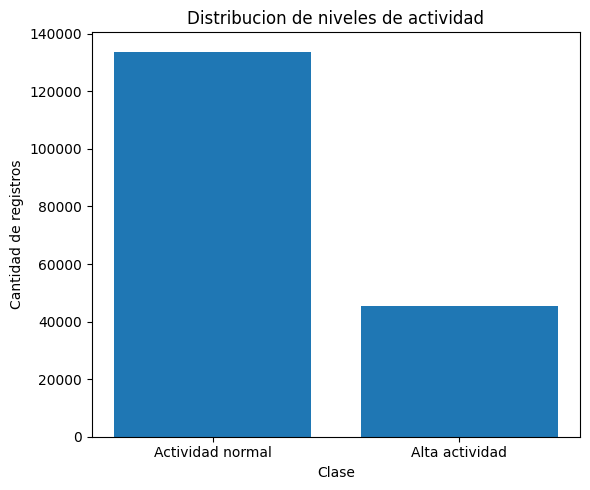

In [26]:
# Mostramos la cantidad de registros de actividad normal y alta
clases = (
    modelo_df
    .groupBy("alta_actividad")
    .count()
    .orderBy("alta_actividad")
)

clases_pd = clases.toPandas()

plt.figure(figsize=(6,5))

plt.bar(
    clases_pd["alta_actividad"].astype(str),
    clases_pd["count"]
)

plt.title("Distribucion de niveles de actividad")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")

plt.xticks(
    [0, 1],
    ["Actividad normal", "Alta actividad"]
)

plt.tight_layout()
plt.show()

In [27]:
# Comparamos los resultados reales con las predicciones del modelo
comparacion = (
    predicciones
    .groupBy(
        "alta_actividad",
        "prediction"
    )
    .count()
    .orderBy(
        "alta_actividad",
        "prediction"
    )
)

comparacion.show()

[Stage 148:>                                                        (0 + 3) / 3]

+--------------+----------+-----+
|alta_actividad|prediction|count|
+--------------+----------+-----+
|             0|       0.0|25812|
|             0|       1.0|  910|
|             1|       0.0| 1536|
|             1|       1.0| 7529|
+--------------+----------+-----+



/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

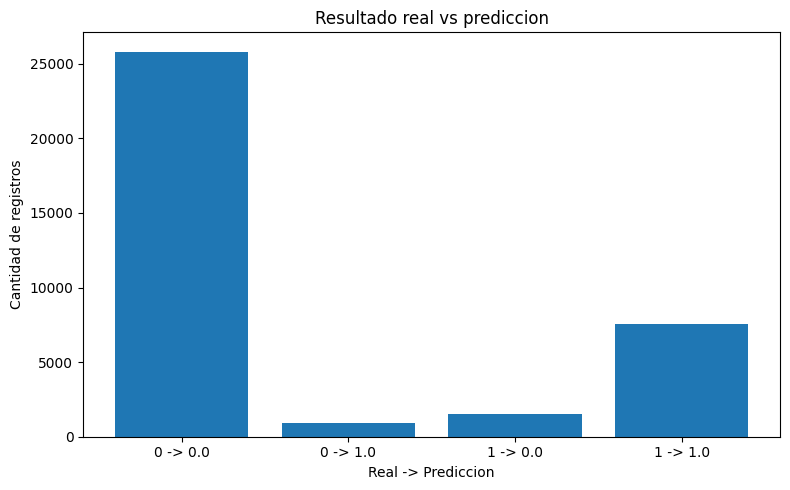

In [28]:
# Convertimos la comparacion a Pandas
comparacion_pd = comparacion.toPandas()

comparacion_pd["resultado"] = (
    comparacion_pd["alta_actividad"].astype(str)
    + " -> "
    + comparacion_pd["prediction"].astype(str)
)

plt.figure(figsize=(8,5))

plt.bar(
    comparacion_pd["resultado"],
    comparacion_pd["count"]
)

plt.title("Resultado real vs prediccion")
plt.xlabel("Real -> Prediccion")
plt.ylabel("Cantidad de registros")

plt.tight_layout()
plt.show()